# Just data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [148]:
data_red = pd.read_csv('winequality-red.csv', sep=';')
data_white = pd.read_csv('winequality-white.csv', sep=';')

In [149]:
data_white.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [150]:
data_red['is_red'] = 1
data_white['is_red'] = 0

data = pd.concat([data_red, data_white], ignore_index=True)
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [92]:
data_white.count()
data.count()

,0
fixed acidity,6497
volatile acidity,6497
citric acid,6497
residual sugar,6497
chlorides,6497
free sulfur dioxide,6497
total sulfur dioxide,6497
density,6497
pH,6497
sulphates,6497


In [151]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [152]:
data['total/free sulfur'] = data['total sulfur dioxide'] / data['free sulfur dioxide']
data['alco * sugar'] = data['alcohol'] * data['residual sugar']
conditions = [
    data['alcohol'] < 10,
    (data['alcohol'] >= 10) & (data['alcohol'] <= 12),
    data['alcohol'] > 12
]

choices = ['weak', 'medium', 'strong']

data['alcohol strongness'] = np.select(conditions, choices, default='medium')
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red,total/free sulfur,alco * sugar,alcohol strongness
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1,3.090909,17.86,weak
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1,2.680000,25.48,weak
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1,3.600000,22.54,weak
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1,3.529412,18.62,weak
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1,3.090909,17.86,weak


In [153]:
from sklearn.preprocessing import OneHotEncoder

In [155]:
ohe = OneHotEncoder(sparse_output=False)
new_data = ohe.fit_transform(data[['alcohol strongness']])
encoded = pd.DataFrame(new_data, columns=ohe.get_feature_names_out(), index=data.index)
data = pd.concat([data.drop(columns=['alcohol', 'alcohol strongness']), encoded], axis=1)
data

KeyError: "None of [Index(['alcohol strongness'], dtype='object')] are in the [columns]"

In [156]:
skewed_features = ['residual sugar', 'chlorides', 'free sulfur dioxide',
                   'total sulfur dioxide', 'sulphates']

for col in skewed_features:
    data_ohe[col] = np.log1p(data_ohe[col])

In [157]:
x_red = data_red.drop(columns=['quality']).values
y_red = data_red['quality'].values

x_white = data_white_ohe.drop(columns=['quality']).values
y_white = data_white['quality'].values

x = data.drop(columns=['quality'])
y = data['quality']

x_red_train, x_red_test, y_red_train, y_red_test = train_test_split(x_red, y_red, test_size=0.2, random_state=42)
x_white_train, x_white_test, y_white_train, y_white_test = train_test_split(x_white, y_white, test_size=0.2, random_state=42)

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [54]:
x_white_train

array([[7.3 , 0.17, 0.36, ..., 0.  , 1.  , 0.  ],
       [6.3 , 0.25, 0.44, ..., 0.  , 0.  , 1.  ],
       [5.6 , 0.32, 0.33, ..., 1.  , 0.  , 0.  ],
       ...,
       [7.6 , 0.27, 0.52, ..., 1.  , 0.  , 0.  ],
       [6.3 , 0.24, 0.29, ..., 1.  , 0.  , 0.  ],
       [8.1 , 0.27, 0.35, ..., 1.  , 0.  , 0.  ]])

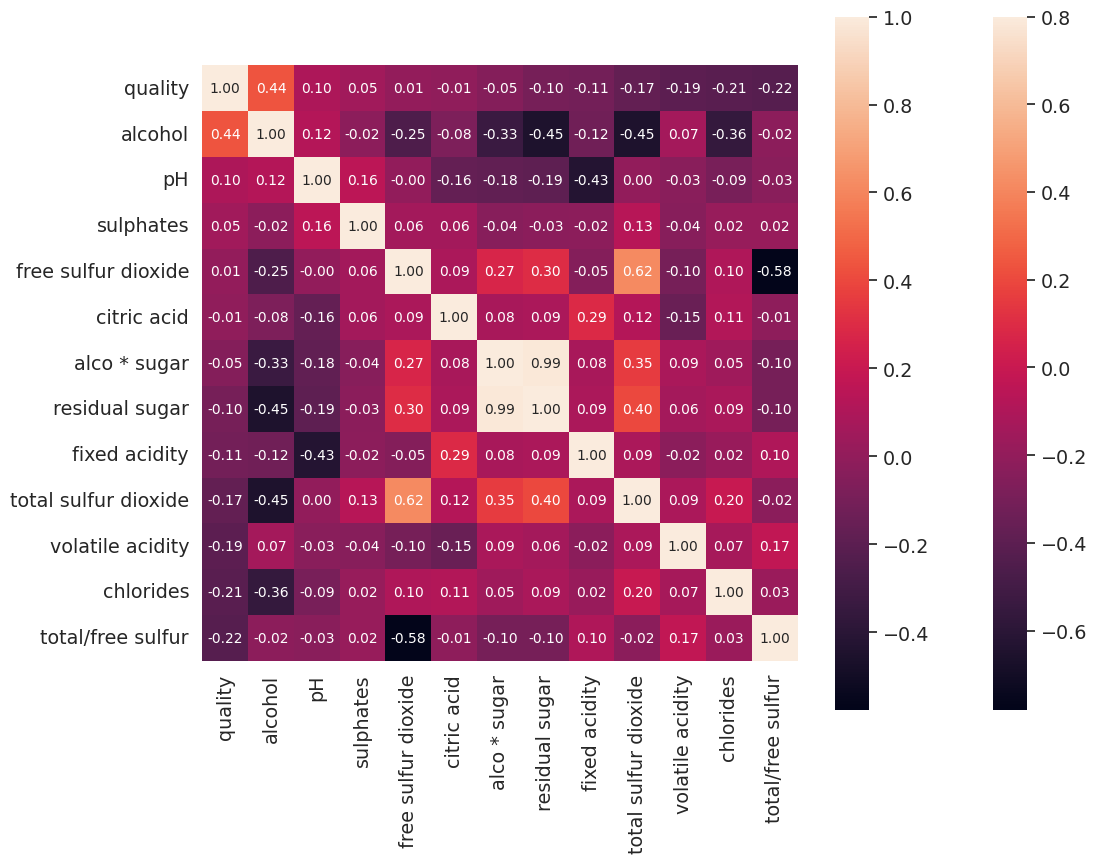

In [14]:
corrmat = data_white.corr()
f, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corrmat, vmax=.8, square=True);
k = 13
cols = corrmat.nlargest(k, 'quality')['quality'].index
cm = np.corrcoef(data_white[cols].values.T)
sns.set(font_scale=1.25)
hm = sns.heatmap(cm, cbar=True, annot=True, square=True, fmt='.2f', annot_kws={'size': 10}, yticklabels=cols.values, xticklabels=cols.values)
plt.show()

# Scaling

In [103]:
scaler_red = StandardScaler()
scaler_red.fit(x_red_train)
x_red_train_scaled = scaler_red.transform(x_red_train)
x_red_test_scaled = scaler_red.transform(x_red_test)

scaler_white = StandardScaler()
scaler_white.fit(x_white_train)
x_white_train_scaled = scaler_white.transform(x_white_train)
x_white_test_scaled = scaler_white.transform(x_white_test)

scaler = StandardScaler()
scaler.fit(x_train)
x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Baseline

In [45]:
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_absolute_error

In [46]:
baseline = np.mean(y_white_train)
pred_baseline = np.full_like(y_white_test, baseline, dtype=float)

rmse_baseline = root_mean_squared_error(y_white_test, pred_baseline)
mae_baseline = mean_absolute_error(y_white_test, pred_baseline)

print(rmse_baseline, mae_baseline)

0.8806495608493429 0.6749789042722756


# Linear Regression

я сдаюсь, линейку на этом датасете невозможно сделать <0.7

In [96]:
from sklearn.linear_model import LinearRegression

In [104]:
model_red = LinearRegression()

model_linear = LinearRegression()

In [105]:
model_red.fit(x_red_train_scaled, y_red_train)

model_linear.fit(x_train_scaled, y_train)

LinearRegression()

In [106]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV

# Попробуем Ridge с подбором параметра alpha
ridge = Ridge()
param_grid = {'alpha': [0.01, 0.1, 1, 10, 100]}

grid_ridge = GridSearchCV(ridge, param_grid, scoring='neg_root_mean_squared_error', cv=5)
grid_ridge.fit(x_train_scaled, y_train)

best_ridge = grid_ridge.best_estimator_
pred_ridge = best_ridge.predict(x_test_scaled)

rmse_ridge = root_mean_squared_error(y_test, pred_ridge)
print(f'Ridge RMSE: {rmse_ridge}, MAE: {mean_absolute_error(y_test, pred_ridge)}')

Ridge RMSE: 0.7275731097076806, MAE: 0.5573122490991539


In [107]:
# pred_red = model_red.predict(x_red_test_scaled)
# rmse_red = root_mean_squared_error(y_red_test, pred_red)
# с этого момента red не юзается

pred_linear = model_linear.predict(x_test_scaled)

rmse_linear = root_mean_squared_error(y_test, pred_linear)
mae_linear = mean_absolute_error(y_test, pred_linear)

print(f'rmse : {rmse_linear}, mae : {mae_linear}')

rmse : 0.727848713933762, mae : 0.5576795058158348


# Random Forest

In [122]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

In [158]:
random_forest = RandomForestRegressor(n_estimators=200, criterion='squared_error', random_state=42)

random_forest.fit(x_train, y_train)

RandomForestRegressor(n_estimators=200, random_state=42)

In [159]:
forest_pred = random_forest.predict(x_test)
rmse_forest = root_mean_squared_error(y_test, forest_pred)
mae_forest = mean_absolute_error(y_test, forest_pred)
print(f'rmse : {rmse_forest}, mae : {mae_forest}')

rmse : 0.6084124360232065, mae : 0.43345384615384613


только на белом
rmse : 0.5876840137352725, mae : 0.4172142857142857

In [160]:
random_forest.feature_importances_

array([0.05301016, 0.12455082, 0.06424677, 0.03537154, 0.05985656,
       0.05809826, 0.0628687 , 0.06766154, 0.06417197, 0.07326694,
       0.0006673 , 0.09388107, 0.06745179, 0.02736959, 0.04613794,
       0.10138907])

# Gradient Boosting Regression

In [161]:
from sklearn.ensemble import GradientBoostingRegressor

тут сразу сделаем подбор гиперпараметров

In [128]:
grid = {
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 300, 500],
    'max_depth': [3, 4, 5],
    'subsample': [0.8, 1.0]
}

gradient_boosting = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=grid,
    scoring='neg_root_mean_squared_error',
    cv=5,
    refit=True,
    n_jobs=-1
)

gradient_boosting.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=GradientBoostingRegressor(random_state=42),
             n_jobs=-1,
             param_grid={'learning_rate': [0.01, 0.05, 0.1],
                         'max_depth': [3, 4, 5],
                         'n_estimators': [100, 300, 500],
                         'subsample': [0.8, 1.0]},
             scoring='neg_root_mean_squared_error')

In [130]:
gradient_boosting.best_params_

{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 500, 'subsample': 0.8}

{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 500, 'subsample': 0.8}

In [162]:
gradient_boosting = GradientBoostingRegressor(learning_rate=0.05, max_depth=5, n_estimators=500, subsample=0.8)
gradient_boosting.fit(x_train, y_train)

GradientBoostingRegressor(learning_rate=0.05, max_depth=5, n_estimators=500,
                          subsample=0.8)

In [163]:
# gradient_predict = gradient_boosting.best_estimator_.predict(x_white_test)
gradient_predict = gradient_boosting.predict(x_test)

rmse_gradient = root_mean_squared_error(y_test, gradient_predict)
mae_gradient = mean_absolute_error(y_test, gradient_predict)

print(f'rmse : {rmse_gradient}, mae : {mae_gradient}')

rmse : 0.6217674255269288, mae : 0.46997050421862724


# Feature Importances

In [164]:
features = pd.DataFrame({
    'column' : data.drop(columns=['quality']).columns,
    'linear weights' : model_linear.coef_,
    'rforest importances' : random_forest.feature_importances_,
    'gboosting importances' : gradient_boosting.feature_importances_
})

features

,column,linear weights,rforest importances,gboosting importances
0,fixed acidity,0.169058,0.053010,0.048016
1,volatile acidity,-0.239880,0.124551,0.122546
2,citric acid,-0.007912,0.064247,0.057667
3,residual sugar,0.019459,0.035372,0.033837
4,chlorides,-0.022839,0.059857,0.053829
5,free sulfur dioxide,0.037016,0.058098,0.053805
6,total sulfur dioxide,-0.026015,0.062869,0.069576
7,density,-0.464621,0.067662,0.092077
8,pH,0.107362,0.064172,0.059549
9,sulphates,0.133534,0.073267,0.068010


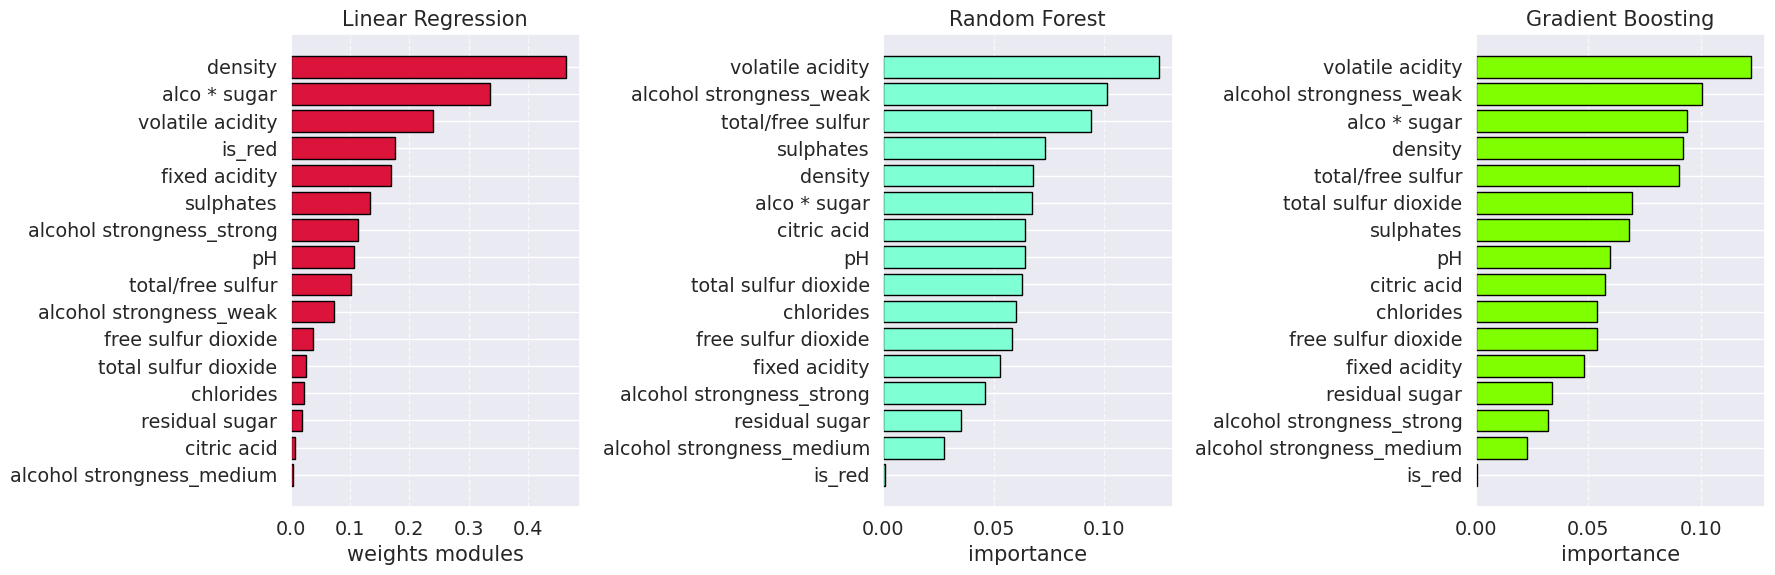

In [165]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

feat_lr = features.copy()
feat_lr['abs_weight'] = feat_lr['linear weights'].abs()
feat_lr = feat_lr.sort_values(by='abs_weight', ascending=True)
axes[0].barh(feat_lr['column'], feat_lr['abs_weight'], color='crimson', edgecolor='black')
axes[0].set_title('Linear Regression')
axes[0].set_xlabel('weights modules')
axes[0].grid(axis='x', linestyle='--', alpha=0.7)

feat_rf = features.sort_values(by='rforest importances', ascending=True)
axes[1].barh(feat_rf['column'], feat_rf['rforest importances'], color='aquamarine', edgecolor='black')
axes[1].set_title('Random Forest')
axes[1].set_xlabel('importance')
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

feat_gb = features.sort_values(by='gboosting importances', ascending=True)
axes[2].barh(feat_gb['column'], feat_gb['gboosting importances'], color='chartreuse', edgecolor='black')
axes[2].set_title('Gradient Boosting')
axes[2].set_xlabel('importance')
axes[2].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Проанализируем полученное

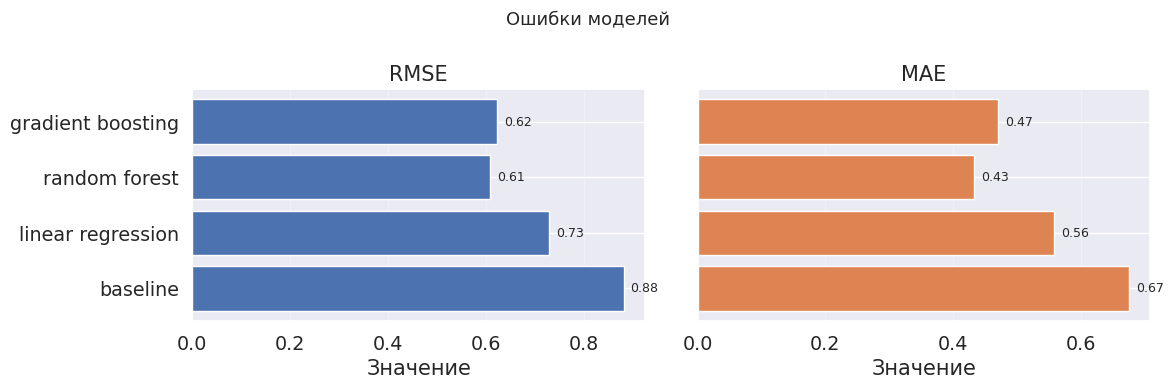

In [167]:
errors = pd.DataFrame({
    'model' : ['baseline', 'linear regression', 'random forest', 'gradient boosting'],
    'rmse' : [rmse_baseline, rmse_linear, rmse_forest, rmse_gradient],
    'mae' : [mae_baseline, mae_linear, mae_forest, mae_gradient]
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, metric, color in zip(axes, ['rmse', 'mae'], ['#4C72B0', '#DD8452']):
    bars = ax.barh(errors['model'], errors[metric], color=color)
    ax.set_title(metric.upper())
    ax.set_xlabel('Значение')
    ax.grid(axis='x', alpha=0.3)
    for bar in bars:
        w = bar.get_width()
        ax.annotate(f'{w:.2f}', xy=(w, bar.get_y() + bar.get_height()/2),
                    xytext=(5, 0), textcoords='offset points',
                    va='center', fontsize=9)

plt.suptitle('Ошибки моделей', fontsize=13)
plt.tight_layout()
plt.show()

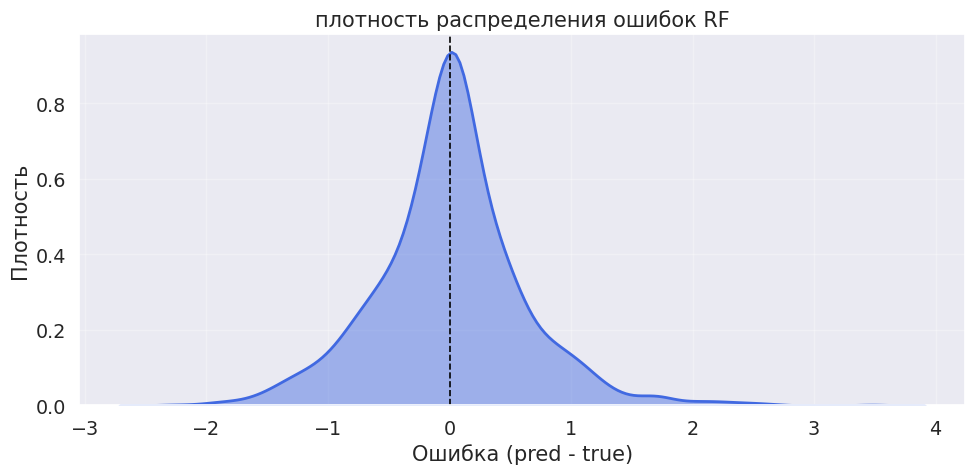

In [178]:
rf_errors = forest_pred - y_test

plt.figure(figsize=(10, 5))

sns.kdeplot(rf_errors, fill=True, color='royalblue', alpha=0.45, linewidth=2)

plt.axvline(0, color='black', linestyle='--', linewidth=1.2)
plt.xlabel('Ошибка (pred - true)')
plt.ylabel('Плотность')
plt.title('плотность распределения ошибок RF')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [183]:
worst_idx = np.argmax(np.abs(rf_errors))
worst_pos = worst_idx
print(f'индекс в тестовой {worst_idx}')
print(f'y_true {y_test.iloc[worst_idx]}')
print(f'predict {forest_pred[worst_idx]:.3f}')
print(f'loss {rf_errors.iloc[worst_idx]:.3f}')

pd.Series(x_train.iloc[worst_idx], index=x_train.columns)

индекс в тестовой 871
y_true 3
predict 6.475
loss 3.475


,2239
fixed acidity,5.600000
volatile acidity,0.235000
citric acid,0.290000
residual sugar,1.200000
chlorides,0.047000
free sulfur dioxide,33.000000
total sulfur dioxide,127.000000
density,0.991000
pH,3.340000
sulphates,0.500000


In [184]:
print(f'Позиция в тестовой выборке: {worst_pos}')

# 1. Истинное значение (по позиции)
print(f'y_true (по позиции): {y_test.iloc[worst_pos]}')

# 2. Предсказание (numpy массив, тут работает обычный индекс)
print(f'predict: {forest_pred[worst_pos]:.3f}')

# 3. Ошибка (Pandas Series, нужен iloc)
print(f'loss: {rf_errors.iloc[worst_pos]:.3f}')

# 4. Оригинальный индекс этой строки в общем датафрейме data
original_index = y_test.index[worst_pos]
print(f'Оригинальный индекс в data: {original_index}')
# Скорее всего, вы увидите здесь 2239

# 5. Смотрим на признаки, которые подавались в модель (из x_test)
print("\nПризнаки, которые видела модель:")
print(x_test.iloc[worst_pos])

Позиция в тестовой выборке: 871
y_true (по позиции): 3
predict: 6.475
loss: 3.475
Оригинальный индекс в data: 2339

Признаки, которые видела модель:
fixed acidity                 6.9000
volatile acidity              0.3900
citric acid                   0.4000
residual sugar                4.6000
chlorides                     0.0220
free sulfur dioxide           5.0000
total sulfur dioxide         19.0000
density                       0.9915
pH                            3.3100
sulphates                     0.3700
is_red                        0.0000
total/free sulfur             3.8000
alco * sugar                 57.9600
alcohol strongness_medium     0.0000
alcohol strongness_strong     1.0000
alcohol strongness_weak       0.0000
Name: 2339, dtype: float64


In [191]:
data.iloc[2339]

,2339
fixed acidity,6.9000
volatile acidity,0.3900
citric acid,0.4000
residual sugar,4.6000
chlorides,0.0220
free sulfur dioxide,5.0000
total sulfur dioxide,19.0000
density,0.9915
pH,3.3100
sulphates,0.3700


In [192]:
data_white.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.0
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909,0.0
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639,0.0
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000,0.0
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000,0.0
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000,0.0
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000,0.0
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000,0.0


либо я шиз либо это не похоже на выброс

In [185]:
data_white['quality'].value_counts()

,count
quality,
6,2198
5,1457
7,880
8,175
4,163
3,20
9,5


скорее всего не выброс, в меру малого колчисетва 'троечных' вин модель просто не выкупила

<Axes: >

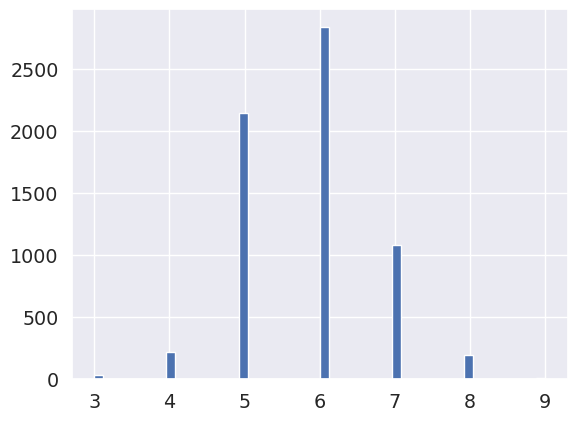

In [188]:
data['quality'].hist(bins=50)